# 03 — Validation croisée par modèle de côlon & Ablation multi-graines

Ce notebook exécute le protocole rigoureux sans fuite anatomique :
1. **Découpage strict par modèle de côlon** (`cecum`, `desc`, `sigmoid`, `trans`) : toutes les séquences/textures d'un même modèle physique restent ensemble (`validate_no_model_leakage`).
   - **Pli 1 (`sigmoid`) :** `train = cecum + trans` (6 séq.) | `val = desc_t4_a` | `test = sigmoid_t2_a, sigmoid_t3_a`.
   - **Pli 2 (`trans`, validation croisée) :** `train = cecum + sigmoid` (4 séq.) | `val = desc_t4_a` | `test = trans_t1_a..t3_b`.
2. **Hyperparamètres v2 strictement conservés** (`epochs=12`, `lr=5e-5`, `weight_decay=1e-2`, `lr_scheduler="cosine"`, `train_neck=False`, `color_augment=True`).
3. **Ablation 3 graines** (`42, 123, 2026`) : `baseline`, `grad_only`, `norm_only`, `grad_norm`, avec affichage explicite `(n=1)` si une seule graine est présente et `moyenne ± écart-type` dès `n >= 2`.
4. **Réévaluation sur le même test** de `Zero-Shot DAV2-Small`, `v2` (Lot 1, sans fuite) et des checkpoints `v3` existants (avec détection automatique de fuite éventuelle), plus grille qualitative 6 colonnes.

In [1]:
import importlib.util
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

# === PARAMÈTRES UTILISATEUR ===
REPO_URL = "https://github.com/hanmaZi/endo-depth.git"
DRIVE_PROJECT_DIR = Path("/content/drive/MyDrive/endo-depth")
DATASET_NAME = "c3vd"   # "c3vd" ou "simcol3d"

EXPECTED_SEQUENCES = [
    "cecum_t1_a",
    "cecum_t2_a",
    "desc_t4_a",
    "sigmoid_t2_a",
    "sigmoid_t3_a",
    "trans_t1_a",
    "trans_t2_a",
    "trans_t3_a",
    "trans_t3_b",
]
# Liste des séquences à copier/extraire depuis Drive (les dossiers déjà extraits sont sautés)
SELECTED_SEQUENCES = list(EXPECTED_SEQUENCES)

# Plis par modèle de côlon : mets ["sigmoid", "trans"] pour la validation croisée sur 2 modèles,
# ou ["sigmoid"] d'abord si le quota GPU Colab est serré.
CV_FOLDS = ["sigmoid", "trans"]

# Hyperparamètres v2 conservés à l'identique :
EPOCHS = 12
BATCH_SIZE = 4
RUN_MODE = "ablation_full"  # "ablation_full" (4 variantes x 3 graines) ou "v3_pair" (baseline + grad_norm, seed 42)
ABLATION_SEEDS = [42, 123, 2026]
AUTO_RESUME = True
REEVAL_PRIOR_ON_SAME_TEST = True  # Réévalue Zero-Shot, v2 et v3 sur le même test de chaque pli

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    if Path("/content/endo-depth/.git").is_dir():
        PROJECT_ROOT = Path("/content/endo-depth")
        !git -C {PROJECT_ROOT} pull --ff-only || true
    elif REPO_URL:
        !git clone {REPO_URL} /content/endo-depth
        PROJECT_ROOT = Path("/content/endo-depth")
    elif (DRIVE_PROJECT_DIR / "src").is_dir():
        PROJECT_ROOT = DRIVE_PROJECT_DIR
    else:
        raise RuntimeError(
            "Dépôt endo-depth introuvable. Place-le dans MyDrive/endo-depth ou renseigne REPO_URL."
        )
    DATA_BASE = DRIVE_PROJECT_DIR / "data"
    LOCAL_DATA_BASE = Path("/content/data")
    RESULTS_DIR = DRIVE_PROJECT_DIR / "results"
else:
    cwd = Path.cwd()
    PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd
    DATA_BASE = PROJECT_ROOT / "data"
    LOCAL_DATA_BASE = PROJECT_ROOT / "data"
    RESULTS_DIR = PROJECT_ROOT / "results"

os.chdir(PROJECT_ROOT)
sys.path = [p for p in sys.path if "drive/MyDrive/endo-depth" not in p]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
for _m in [k for k in sys.modules if k == "src" or k.startswith("src.")]:
    del sys.modules[_m]

missing = [p for p in ["transformers", "timm", "yaml", "cv2"] if importlib.util.find_spec(p) is None]
if missing:
    %pip install -q "transformers>=4.45.0" timm pyyaml opencv-python-headless

import src.datasets
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("PROJECT_ROOT       :", PROJECT_ROOT)
print("src chargé         :", src.datasets.__file__)
print("RESULTS_DIR        :", RESULTS_DIR)
print("CV_FOLDS           :", CV_FOLDS, "| RUN_MODE :", RUN_MODE, "| SEEDS :", ABLATION_SEEDS)

Mounted at /content/drive
Cloning into '/content/endo-depth'...
remote: Enumerating objects: 167, done.
remote: Counting objects: 100% (167/167), done.
remote: Compressing objects: 100% (105/105), done.
remote: Total 167 (delta 88), reused 126 (delta 55), pack-reused 0 (from 0)
Receiving objects: 100% (167/167), 3.21 MiB | 15.24 MiB/s, done.
Resolving deltas: 100% (88/88), done.
PROJECT_ROOT : /content/endo-depth
src chargé   : /content/endo-depth/src/datasets/__init__.py
RESULTS_DIR  : /content/drive/MyDrive/endo-depth/results


In [2]:
import torch
from src.datasets import (
    C3VD_MODEL_CV_FOLDS,
    assign_sequence_splits,
    discover_c3vd_records,
    resolve_dataset_dir,
    summarize_records_by_sequence,
    validate_no_model_leakage,
)

print("CUDA dispo :", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

selected_arg = SELECTED_SEQUENCES if SELECTED_SEQUENCES else None
all_expected_selected = bool(EXPECTED_SEQUENCES) and (
    not selected_arg or set(EXPECTED_SEQUENCES).issubset(set(selected_arg))
)
expected_for_resolve = EXPECTED_SEQUENCES if all_expected_selected else None

dataset_dir, DATASET_NAME, is_demo = resolve_dataset_dir(
    DATASET_NAME,
    drive_data_base=DATA_BASE,
    local_data_base=LOCAL_DATA_BASE,
    demo_fallback_dir=RESULTS_DIR / "_demo_c3vd",
    expected_sequences=expected_for_resolve,
    selected_sequences=selected_arg,
)

FOLDS_SPLITS = {}
if is_demo:
    print("[ATTENTION] Aucun dataset réel détecté -> mode démo synthétique C3VD activé.")
    EPOCHS = min(EPOCHS, 3)
    FOLDS_SPLITS["demo"] = None
else:
    print("Dataset préparé et lu depuis :", dataset_dir)
    if DATASET_NAME == "c3vd":
        recs = discover_c3vd_records(
            dataset_dir,
            expected_sequences=expected_for_resolve,
            include_sequences=selected_arg,
        )
        seq_counts = summarize_records_by_sequence(recs)
        print("Images par séquence :", seq_counts)
        for fold_name in CV_FOLDS:
            fold_def = C3VD_MODEL_CV_FOLDS.get(fold_name)
            if fold_def and all(s in seq_counts for grp in fold_def.values() for s in grp):
                validate_no_model_leakage(fold_def)
                FOLDS_SPLITS[fold_name] = fold_def
            else:
                auto_s = assign_sequence_splits(recs, split_by="model")
                validate_no_model_leakage(auto_s)
                FOLDS_SPLITS[fold_name] = auto_s
            print(f"\n[Pli '{fold_name}' — sans fuite de modèle] :")
            for sp in ("train", "val", "test"):
                sp_seqs = FOLDS_SPLITS[fold_name][sp]
                sp_frames = sum(seq_counts.get(s, 0) for s in sp_seqs)
                print(f"  {sp:5s} ({sp_frames:4d} img) : {sp_seqs}")
    else:
        FOLDS_SPLITS["default"] = None

CUDA dispo : True
GPU : Tesla T4
[Auto-detect] Dossier(s) C3VD trouvé(s) dans MyDrive : [PosixPath('/content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips')]
[Source] /content/drive/MyDrive/endo-depth/endo-depth/data/c3vd_zips contient : ['cecum_t1_a', 'desc_t4_a', 'trans_t1_a']
[Copy] cecum_t1_a/ -> /content/data/c3vd/cecum_t1_a
[Copy] desc_t4_a/ -> /content/data/c3vd/desc_t4_a
[Copy] trans_t1_a/ -> /content/data/c3vd/trans_t1_a
Dataset préparé et lu depuis : /content/data/c3vd


In [3]:
from src.eval import evaluate_checkpoint_on_sequences
from src.train import run_training
from src.utils import load_config, save_json

ABLATION_VARIANTS = {
    "baseline": ("Baseline (L1 + SiLog)", "c3vd_v3_baseline.yaml"),
    "grad_only": ("Gradients seuls", "c3vd_v3_grad_only.yaml"),
    "norm_only": ("Normales seules", "c3vd_v3_norm_only.yaml"),
    "grad_norm": ("Contrib complète (Grad + Norm)", "c3vd_v3_grad_norm.yaml"),
}

if RUN_MODE == "ablation_full":
    variants_to_run = ["baseline", "grad_only", "norm_only", "grad_norm"]
    seeds_to_run = list(ABLATION_SEEDS)
else:
    variants_to_run = ["baseline", "grad_norm"]
    seeds_to_run = [ABLATION_SEEDS[0]]


def prepare_cv_config(yaml_name: str, fold_name: str, variant_key: str, seed: int) -> dict:
    cfg = load_config(PROJECT_ROOT / "configs" / yaml_name)
    exp_name = f"c3vd_cv_{fold_name}_{variant_key}_seed{seed}"
    cfg["experiment_name"] = exp_name
    cfg["seed"] = int(seed)
    cfg["data"]["dataset_name"] = DATASET_NAME
    cfg["data"]["dataset_path"] = str(dataset_dir)
    cfg["data"]["expected_sequences"] = None if (is_demo or not expected_for_resolve) else expected_for_resolve
    cfg["data"]["selected_sequences"] = None if (is_demo or not selected_arg) else selected_arg
    cfg["data"]["split_by"] = "model"
    cfg["data"]["sequence_splits"] = FOLDS_SPLITS.get(fold_name)
    cfg["data"]["batch_size"] = BATCH_SIZE
    cfg["paths"]["results_dir"] = str(RESULTS_DIR)
    cfg["paths"]["checkpoint_dir"] = str(RESULTS_DIR / exp_name / "checkpoints")
    cfg["training"]["epochs"] = EPOCHS
    if DATASET_NAME == "simcol3d":
        cfg["data"]["max_depth_mm"] = 200.0
        cfg["evaluation"]["max_depth"] = 200.0
    return cfg


active_folds = list(FOLDS_SPLITS.keys())
total_runs = len(active_folds) * len(variants_to_run) * len(seeds_to_run)
run_idx = 0

prior_candidates = [
    ("Zero-Shot DAV2-Small", None, "c3vd_zeroshot.yaml", []),
    ("Baseline LoRA v2 (Lot 1)", "c3vd_lora_baseline_v2", None, ["cecum_t1_a"]),
    ("Contrib LoRA v2 (Lot 1)", "c3vd_lora_grad_norm_v2", None, ["cecum_t1_a"]),
    ("Baseline LoRA v3 (split texture)", "c3vd_v3_baseline_seed42", None, None),
    ("Contrib LoRA v3 (split texture)", "c3vd_v3_grad_norm_seed42", None, None),
]

for fold_name in active_folds:
    # 1) Réévaluation rapide dès le début du pli (évite d'attendre la fin de l'ablation)
    if REEVAL_PRIOR_ON_SAME_TEST and (not is_demo) and DATASET_NAME == "c3vd":
        fold_splits = FOLDS_SPLITS.get(fold_name)
        prior_out_file = RESULTS_DIR / f"same_test_{fold_name}_prior.json"
        if fold_splits and not (AUTO_RESUME and prior_out_file.is_file()):
            test_seqs = fold_splits["test"]
            same_test_results = {}
            print(f"\n=== Réévaluation antérieure sur le test du pli '{fold_name}' ({test_seqs}) ===")
            for label, exp_dir_name, zs_yaml, fallback_train in prior_candidates:
                if zs_yaml is not None:
                    cfg_eval = load_config(PROJECT_ROOT / "configs" / zs_yaml)
                    ckpt_path = None
                    train_seqs_used = []
                else:
                    exp_dir = RESULTS_DIR / exp_dir_name
                    ckpt_path = exp_dir / "checkpoints" / "best.pt"
                    cfg_file = exp_dir / "config_used.yaml"
                    if not (ckpt_path.is_file() and cfg_file.is_file()):
                        continue
                    cfg_eval = load_config(cfg_file)
                    sp = cfg_eval.get("data", {}).get("sequence_splits") or {}
                    train_seqs_used = sp.get("train") or (
                        fallback_train if fallback_train is not None else []
                    )
                cfg_eval["data"]["batch_size"] = BATCH_SIZE
                res = evaluate_checkpoint_on_sequences(
                    cfg_eval,
                    dataset_dir=dataset_dir,
                    test_sequences=test_seqs,
                    checkpoint_path=ckpt_path,
                    align_mode="median",
                    train_sequences_used=train_seqs_used,
                )
                tag = " [⚠️ FUITE MODÈLE]" if res["has_model_leakage"] else " [zéro fuite]"
                print(f"  -> {label}{tag} : {res['metrics']}")
                same_test_results[label] = res
            save_json(same_test_results, prior_out_file)

    # 2) Entraînements multi-variantes x 3 graines sur ce pli
    for variant_key in variants_to_run:
        label, yaml_name = ABLATION_VARIANTS[variant_key]
        for seed in seeds_to_run:
            run_idx += 1
            print(f"\n=== [{run_idx}/{total_runs}] Pli={fold_name} | {label} | seed={seed} ===")
            cfg = prepare_cv_config(yaml_name, fold_name, variant_key, seed)
            run_training(cfg, auto_resume=AUTO_RESUME)


=== 1/2 : Entraînement Baseline LoRA (L1 + SiLog) ===
[Info] Périphérique utilisé : cuda
[C3VD] Séquences trouvées (total=485 frames) : {'cecum_t1_a': 276, 'desc_t4_a': 148, 'trans_t1_a': 61}
[Info] Dataset c3vd : train=276, val=148, test=61


config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 99.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/287 [00:00<?, ?it/s]

[Info] Modèle depth_anything_v2_lora : 2,875,971 / 24,932,547 paramètres entraînables (11.54%)


... (30 outputs left out)

[Epoch 13/15] loss=0.7569 (l1=0.624, grad=0.131, norm=0.086) | val_AbsRel=0.2077, val_RMSE=8.427, val_d1=0.5972


[Epoch 14/15] loss=0.7565 (l1=0.627, grad=0.126, norm=0.085) | val_AbsRel=0.1941, val_RMSE=7.700, val_d1=0.6255


[Epoch 15/15] loss=0.7197 (l1=0.590, grad=0.126, norm=0.085) | val_AbsRel=0.2046, val_RMSE=8.129, val_d1=0.5918


[OK] Entraînement terminé. Test final : {'abs_rel': 0.167094, 'sq_rel': 1.30899, 'rmse': 8.464066, 'rmse_log': 0.221717, 'delta_1': 0.73243, 'delta_2': 0.94126, 'delta_3': 0.987169, 'num_evaluated_frames': 61.0}


=== Tableau comparatif sur le split test ===
{
  "Zero-Shot DAV2-Small": {
    "abs_rel": 0.379189,
    "sq_rel": 3.15541,
    "rmse": 8.462212,
    "rmse_log": 0.407756,
    "delta_1": 0.47559,
    "delta_2": 0.751128,
    "delta_3": 0.896981,
    "num_evaluated_frames": 61.0
  },
  "Baseline LoRA (L1+SiLog)": {
    "abs_rel": 0.163542,
    "sq_rel": 1.096292,
    "rmse": 7.446611,
    "rmse_log": 0.209548,
    "delta_1": 0.73986,
    "delta_2": 0.955987,
    "delta_3": 0.992991,
    "num_evaluated_frames": 61.0
  },
  "Contrib LoRA + Grad/Norm": {
    "abs_rel": 0.167094,
    "sq_rel": 1.30899,
    "rmse": 8.464066,
    "rmse_log": 0.221717,
    "delta_1": 0.73243,
    "delta_2": 0.94126,
    "delta_3": 0.987169,
    "num_evaluated_frames": 61.0
  }
}


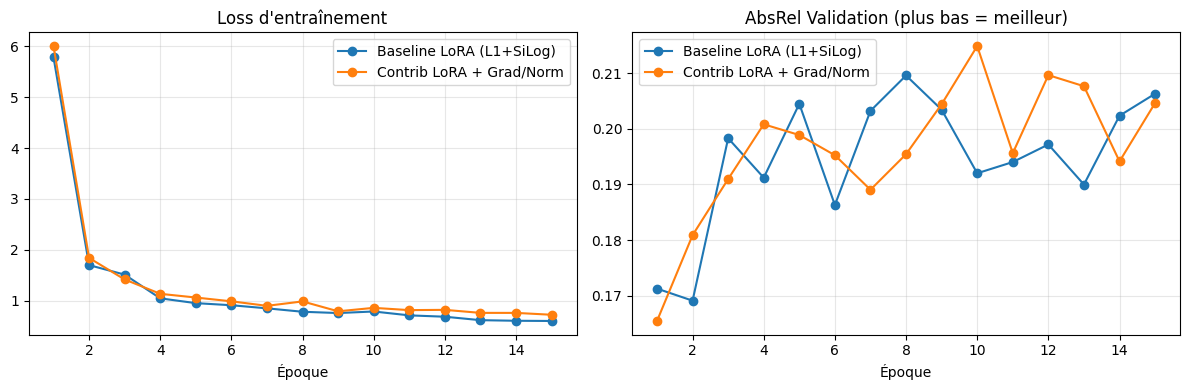

In [4]:
import json
import matplotlib.pyplot as plt
from src.eval import aggregate_ablation_results
from src.utils import save_json

all_cv_summaries = {}

for fold_name in FOLDS_SPLITS.keys():
    print(f"\n====================================================")
    print(f"RÉSULTATS PLI '{fold_name}' (découpage par modèle)")
    print(f"====================================================")
    fold_sp = FOLDS_SPLITS.get(fold_name)
    if fold_sp:
        print("Train :", fold_sp["train"])
        print("Val   :", fold_sp["val"])
        print("Test  :", fold_sp["test"])

    # 1) Modèles antérieurs réévalués sur ce même test
    prior_file = RESULTS_DIR / f"same_test_{fold_name}_prior.json"
    if prior_file.is_file():
        with prior_file.open("r", encoding="utf-8") as f:
            prior_data = json.load(f)
        print("\n--- Comparaison sur ce même test (Zero-Shot, v2, v3) ---")
        for label, res in prior_data.items():
            m = res["metrics"]
            leak = f" [⚠️ FUITE: {res['overlapping_models']}]" if res.get("has_model_leakage") else " [zéro fuite]"
            print(
                f"  {label:34s}{leak:26s} | "
                f"AbsRel={m['abs_rel']:.4f}, RMSE={m['rmse']:.4f}, "
                f"GradMAE={m.get('grad_mae', 0.0):.4f}, d1={m['delta_1']:.4f}"
            )

    # 2) Ablation multi-graines sur ce pli
    variant_runs = {
        variant_key: [f"c3vd_cv_{fold_name}_{variant_key}_seed{s}" for s in ABLATION_SEEDS]
        for variant_key in ("baseline", "grad_only", "norm_only", "grad_norm")
    }
    ablation_fold = aggregate_ablation_results(RESULTS_DIR, variant_runs, align_mode="median")
    if ablation_fold:
        save_json(ablation_fold, RESULTS_DIR / f"ablation_cv_{fold_name}_summary.json")
        all_cv_summaries[fold_name] = ablation_fold
        print(f"\n--- Ablation Pli '{fold_name}' (moyenne ± écart-type, n graines) ---")
        for variant_key, block in ablation_fold.items():
            ov = block["overall"]
            print(
                f"  {variant_key:10s} (n={block['num_seeds']}) | "
                f"AbsRel={ov.get('abs_rel', {}).get('formatted', '-')}, "
                f"RMSE={ov.get('rmse', {}).get('formatted', '-')}, "
                f"GradMAE={ov.get('grad_mae', {}).get('formatted', '-')}, "
                f"d1={ov.get('delta_1', {}).get('formatted', '-')}"
            )
            for seq_name, seq_stats in block.get("per_sequence", {}).items():
                print(
                    f"      [{seq_name}] "
                    f"AbsRel={seq_stats.get('abs_rel', {}).get('formatted', '-')}, "
                    f"RMSE={seq_stats.get('rmse', {}).get('formatted', '-')}, "
                    f"GradMAE={seq_stats.get('grad_mae', {}).get('formatted', '-')}, "
                    f"d1={seq_stats.get('delta_1', {}).get('formatted', '-')}"
                )

    # 3) Courbes (seed 0) du pli
    seed0 = ABLATION_SEEDS[0]
    fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
    has_curve = False
    for variant_key in ("baseline", "grad_only", "norm_only", "grad_norm"):
        hist_file = RESULTS_DIR / f"c3vd_cv_{fold_name}_{variant_key}_seed{seed0}" / "history.json"
        if not hist_file.is_file():
            continue
        has_curve = True
        with hist_file.open("r", encoding="utf-8") as f:
            hist = json.load(f)
        ep = [h["epoch"] for h in hist]
        axes[0].plot(ep, [h["train_loss"]["total"] for h in hist], marker="o", label=variant_key)
        axes[1].plot(ep, [h["val_metrics"]["abs_rel"] for h in hist], marker="o", label=variant_key)
        if "grad_mae" in hist[0].get("val_metrics", {}):
            axes[2].plot(ep, [h["val_metrics"]["grad_mae"] for h in hist], marker="o", label=variant_key)
    if has_curve:
        axes[0].set_title(f"Loss train — Pli {fold_name} (seed={seed0})")
        axes[1].set_title("AbsRel Validation (desc_t4_a)")
        axes[2].set_title("Grad_MAE Validation (mm/px)")
        for ax in axes:
            ax.set_xlabel("Époque")
            ax.legend(fontsize=8)
            ax.grid(alpha=0.3)
        plt.tight_layout()
        plt.savefig(RESULTS_DIR / f"curves_cv_{fold_name}.png", dpi=150)
        plt.show()
    else:
        plt.close(fig)

save_json(all_cv_summaries, RESULTS_DIR / "ablation_all_folds_summary.json")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from src.datasets import build_dataset
from src.metrics import align_prediction, compute_depth_metrics_single
from src.models import build_model
from src.utils import get_device, load_checkpoint

seed0 = ABLATION_SEEDS[0]
device = get_device("auto")

for fold_name in FOLDS_SPLITS.keys():
    base_exp = f"c3vd_cv_{fold_name}_baseline_seed{seed0}"
    contrib_exp = f"c3vd_cv_{fold_name}_grad_norm_seed{seed0}"
    base_ckpt = RESULTS_DIR / base_exp / "checkpoints" / "best.pt"
    contrib_ckpt = RESULTS_DIR / contrib_exp / "checkpoints" / "best.pt"

    if not (base_ckpt.is_file() and contrib_ckpt.is_file()):
        print(f"[Info] Pli '{fold_name}' ignoré (checkpoints absents : {base_ckpt.is_file()=}, {contrib_ckpt.is_file()=}).")
        continue

    cfg_base_vis = prepare_cv_config("c3vd_v3_baseline.yaml", fold_name, "baseline", seed0)
    cfg_contrib_vis = prepare_cv_config("c3vd_v3_grad_norm.yaml", fold_name, "grad_norm", seed0)

    ds_test = build_dataset(cfg_base_vis, split="test")
    by_seq = {}
    for i, rec in enumerate(ds_test.records):
        by_seq.setdefault(rec.sequence_name, []).append(i)
    vis_indices = []
    for seq_name in sorted(by_seq):
        idxs = by_seq[seq_name]
        picks = [idxs[len(idxs) // 4], idxs[(3 * len(idxs)) // 4]] if len(idxs) >= 4 else [idxs[0]]
        vis_indices.extend(picks[:2])
    vis_indices = vis_indices[:4]

    model_base = build_model(cfg_base_vis).to(device)
    load_checkpoint(base_ckpt, model=model_base, device=device)
    model_base.eval()

    model_contrib = build_model(cfg_contrib_vis).to(device)
    load_checkpoint(contrib_ckpt, model=model_contrib, device=device)
    model_contrib.eval()

    min_d = float(cfg_base_vis["data"]["min_depth_mm"])
    max_d = float(cfg_base_vis["data"]["max_depth_mm"])

    n_rows = len(vis_indices)
    fig, axes = plt.subplots(n_rows, 6, figsize=(24, 4 * n_rows))
    if n_rows == 1:
        axes = axes[np.newaxis, :]

    with torch.no_grad():
        for row, idx in enumerate(vis_indices):
            sample = ds_test[int(idx)]
            img_t = sample["image"].unsqueeze(0).to(device)
            gt_t = sample["depth"].to(device)
            mask_t = sample["mask"].to(device)

            pred_b = align_prediction(model_base(img_t)[0], gt_t, mask_t, align_mode="median", min_depth=min_d, max_depth=max_d)
            pred_c = align_prediction(model_contrib(img_t)[0], gt_t, mask_t, align_mode="median", min_depth=min_d, max_depth=max_d)

            m_b = compute_depth_metrics_single(pred_b, gt_t, mask_t, min_depth=min_d, max_depth=max_d)
            m_c = compute_depth_metrics_single(pred_c, gt_t, mask_t, min_depth=min_d, max_depth=max_d)

            rgb_np = sample["image"].permute(1, 2, 0).numpy()
            gt_np = gt_t.squeeze(0).cpu().numpy()
            mask_np = mask_t.squeeze(0).cpu().numpy()
            pb_np = pred_b.cpu().numpy()
            pc_np = pred_c.cpu().numpy()
            eb_np = np.abs(pb_np - gt_np)
            ec_np = np.abs(pc_np - gt_np)

            valid_gt = gt_np[mask_np]
            d_vmin = float(np.percentile(valid_gt, 2)) if valid_gt.size else min_d
            d_vmax = float(np.percentile(valid_gt, 98)) if valid_gt.size else max_d
            err_vals = np.concatenate([eb_np[mask_np], ec_np[mask_np]]) if mask_np.any() else np.array([10.0])
            e_vmax = float(np.percentile(err_vals, 95))

            axes[row, 0].imshow(rgb_np)
            axes[row, 0].set_title(f"{sample['sequence']} / {sample['frame_id']}\nRGB")

            axes[row, 1].imshow(np.ma.masked_where(~mask_np, gt_np), cmap="turbo", vmin=d_vmin, vmax=d_vmax)
            axes[row, 1].set_title("Vérité terrain (mm)")

            axes[row, 2].imshow(np.ma.masked_where(~mask_np, pb_np), cmap="turbo", vmin=d_vmin, vmax=d_vmax)
            axes[row, 2].set_title(f"Baseline CV ({fold_name})\nAbsRel={m_b['abs_rel']:.3f} | GradMAE={m_b['grad_mae']:.2f}")

            axes[row, 3].imshow(np.ma.masked_where(~mask_np, pc_np), cmap="turbo", vmin=d_vmin, vmax=d_vmax)
            axes[row, 3].set_title(f"Contrib CV ({fold_name})\nAbsRel={m_c['abs_rel']:.3f} | GradMAE={m_c['grad_mae']:.2f}")

            axes[row, 4].imshow(np.ma.masked_where(~mask_np, eb_np), cmap="magma", vmin=0.0, vmax=e_vmax)
            axes[row, 4].set_title("Erreur |Baseline - GT| (mm)")

            axes[row, 5].imshow(np.ma.masked_where(~mask_np, ec_np), cmap="magma", vmin=0.0, vmax=e_vmax)
            axes[row, 5].set_title("Erreur |Contrib - GT| (mm)")

            for c in range(6):
                axes[row, c].axis("off")

    plt.tight_layout()
    qual_path = RESULTS_DIR / f"qualitative_cv_{fold_name}_baseline_vs_contrib.png"
    plt.savefig(qual_path, dpi=150)
    print(f"[OK] Figure qualitative sauvegardée : {qual_path}")
    plt.show()